In [1]:
"""
Tree-based models on the same features and the same 80/20 split as the
linear models: one decision tree (several depths) and a random forest.
Each model is compared on the validation F1 (best threshold).

Usage: python experiments_trees.py
"""
import time

import numpy as np

from helpers import create_csv_submission
from preprocessing import split_train_val, best_threshold
from run import load_data, build_features            # same features as run.py
from trees import fit_bins, apply_bins, train_tree, predict_tree, tree_depth, \
    train_forest, predict_forest

MAKE_SUBMISSION = False   # True -> retrain the forest on all data and write a CSV


def accuracy(y_true, probs, t):
    return np.mean((probs >= t).astype(int) == y_true)


# ---------------------------------------------------------------------
# Data: same cleaning + one-hot + interactions as run.py
# ---------------------------------------------------------------------
x_train, x_test, y01, test_ids, names = load_data()
x_train, x_test = build_features(x_train, x_test, names)
y01 = y01.astype(int)
print("Features:", x_train.shape[1])

i_tr, i_val = split_train_val(len(x_train))           # same split as everyone
mean, edges = fit_bins(x_train[i_tr])                 # bins learned on train only
xb_tr = apply_bins(x_train[i_tr], mean, edges)
xb_val = apply_bins(x_train[i_val], mean, edges)
y_tr, y_val = y01[i_tr], y01[i_val]

results = []

# ---------------------------------------------------------------------
# 1. One decision tree, several depths
# ---------------------------------------------------------------------
print("\nDecision tree:")
for depth in [4, 6, 8, 10, 12]:
    t0 = time.time()
    tree = train_tree(xb_tr, y_tr, max_depth=depth, min_leaf=50)
    probs = predict_tree(tree, xb_val)
    t, f = best_threshold(y_val, probs)
    print(f"  max_depth = {depth:>2}  F1 = {f:.4f}  acc = {accuracy(y_val, probs, t):.3f}  "
          f"threshold = {t:.2f}  ({time.time() - t0:.1f}s)")
    results.append((f"tree depth {depth}", f))

# ---------------------------------------------------------------------
# 2. Random forest
# ---------------------------------------------------------------------
FOREST = dict(n_trees=50, max_depth=12, min_leaf=50, max_features="sqrt")
print(f"\nRandom forest {FOREST}:")
t0 = time.time()
forest = train_forest(xb_tr, y_tr, **FOREST)
probs = predict_forest(forest, xb_val)
t_forest, f = best_threshold(y_val, probs)
print(f"  F1 = {f:.4f}  acc = {accuracy(y_val, probs, t_forest):.3f}  "
      f"threshold = {t_forest:.2f}  ({time.time() - t0:.1f}s)")
results.append(("random forest", f))

# ---------------------------------------------------------------------
# Summary
# ---------------------------------------------------------------------
print("\nSummary (validation F1):")
for name, f in sorted(results, key=lambda r: -r[1]):
    print(f"  {name:<18} {f:.4f}")

# ---------------------------------------------------------------------
# Optional: submission with the forest (retrained on all the data)
# ---------------------------------------------------------------------
if MAKE_SUBMISSION:
    mean, edges = fit_bins(x_train)
    forest = train_forest(apply_bins(x_train, mean, edges), y01, **FOREST)
    probs_test = predict_forest(forest, apply_bins(x_test, mean, edges))
    y_pred = np.where(probs_test >= t_forest, 1, -1)
    create_csv_submission(test_ids, y_pred, "submission_forest.csv")
    print(f"submission_forest.csv written, {np.mean(y_pred == 1):.1%} predicted positive")


Features: 207

Decision tree:
  max_depth =  4  F1 = 0.3867  acc = 0.822  threshold = 0.18  (8.7s)
  max_depth =  6  F1 = 0.4053  acc = 0.867  threshold = 0.19  (8.1s)
  max_depth =  8  F1 = 0.4087  acc = 0.864  threshold = 0.20  (10.7s)
  max_depth = 10  F1 = 0.4074  acc = 0.859  threshold = 0.19  (13.3s)
  max_depth = 12  F1 = 0.4003  acc = 0.850  threshold = 0.19  (15.3s)

Random forest {'n_trees': 50, 'max_depth': 12, 'min_leaf': 50, 'max_features': 'sqrt'}:
  10/50 trees
  20/50 trees
  30/50 trees
  40/50 trees
  50/50 trees
  F1 = 0.4258  acc = 0.865  threshold = 0.20  (90.1s)

Summary (validation F1):
  random forest      0.4258
  tree depth 8       0.4087
  tree depth 10      0.4074
  tree depth 6       0.4053
  tree depth 12      0.4003
  tree depth 4       0.3867


Saved figures/tree_depth.pdf and figures/tree_depth.png


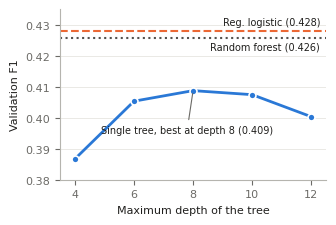

In [2]:
"""
Figure for the report: validation F1 of a single decision tree as a function
of its maximum depth, compared with the random forest and the regularized
logistic regression (same features, same 80/20 split).

The numbers come from experiments_trees.py and run.py.
Usage: python plot_tree_depth.py  -> figures/tree_depth.pdf (+ .png)
"""
import os

import matplotlib.pyplot as plt

# results (validation F1, best threshold)
DEPTHS = [4, 6, 8, 10, 12]
TREE_F1 = [0.3867, 0.4053, 0.4087, 0.4074, 0.4003]
FOREST_F1 = 0.4258       # 50 trees, depth 12, sqrt(D) features per split
LOGISTIC_F1 = 0.4279     # regularized logistic regression (run.py)

# same colors as visualization.ipynb
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#52514e"
INK, MUTED, GRID = "#1f1e1c", "#6b6a66", "#e6e5e0"

plt.rcParams.update({
    "font.size": 8,
    "axes.edgecolor": "#b5b4ae",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.labelcolor": INK,
})

fig, ax = plt.subplots(figsize=(3.4, 2.3))   # one column of the LaTeX template

# reference models: horizontal lines, labelled directly at the right
ax.axhline(LOGISTIC_F1, color=ORANGE, linewidth=1.5, linestyle="--")
ax.axhline(FOREST_F1, color=GRAY, linewidth=1.5, linestyle=":")
ax.text(12.3, LOGISTIC_F1 + 0.0012, f"Reg. logistic ({LOGISTIC_F1:.3f})",
        ha="right", va="bottom", fontsize=7, color=INK)
ax.text(12.3, FOREST_F1 - 0.0012, f"Random forest ({FOREST_F1:.3f})",
        ha="right", va="top", fontsize=7, color=INK)

# single tree
ax.plot(DEPTHS, TREE_F1, color=BLUE, linewidth=2, marker="o", markersize=5,
        markeredgecolor="white", markeredgewidth=1.2, zorder=3)
best = max(range(len(DEPTHS)), key=lambda i: TREE_F1[i])
ax.annotate(f"Single tree, best at depth {DEPTHS[best]} ({TREE_F1[best]:.3f})",
            xy=(DEPTHS[best], TREE_F1[best]), xytext=(DEPTHS[best] - 0.2, 0.395),
            ha="center", fontsize=7, color=INK,
            arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.8))

ax.set_xticks(DEPTHS)
ax.set_xlim(3.5, 12.5)
ax.set_ylim(0.38, 0.435)
ax.set_xlabel("Maximum depth of the tree")
ax.set_ylabel("Validation F1")
ax.grid(axis="x", visible=False)

fig.tight_layout()
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/tree_depth.pdf", bbox_inches="tight")
fig.savefig("figures/tree_depth.png", dpi=200, bbox_inches="tight")
print("Saved figures/tree_depth.pdf and figures/tree_depth.png")